# Moosic 03: PCA (Principal Component Analysis)

**Goal of this notebook:** find out whether PCA makes our playlists better.

**What PCA does, in simple words:** some features move together. Loud songs are usually also energetic, and acoustic
songs are usually calm. PCA combines features that overlap into new "summary" features, called **principal components**,
ordered from most to least informative. Keeping only the strongest ones removes noise, like keeping the key points of a report.

**Plan:**
1. Load and scale the songs (same as notebook 02).
2. Run PCA and see how much information each component holds.
3. Decide how many components to keep.
4. Understand what each component means.
5. Compare K-Means **with and without PCA**.

**Input:** `data/songs_clean.csv` (made by notebook 01)

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sklearn import set_config
set_config(transform_output='pandas')   # scikit-learn returns DataFrames instead of arrays

%matplotlib inline
random_seed = 42                        # same seed everywhere, so results don't change between runs

## 2. Load, clean and scale (same steps as notebook 02)

In [ ]:
songs_df = pd.read_csv('../data/songs_clean.csv').set_index(['name', 'artist'])

# Remove the one broken row (all values 0, loudness -60)
songs_df = songs_df.loc[songs_df['loudness'] != -60]

# The 9 audio features that describe how a song sounds
audio_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
                  'instrumentalness', 'liveness', 'valence', 'tempo']
features_df = songs_df[audio_features]

# PCA needs scaled data, otherwise the feature with the biggest numbers (tempo) dominates the components
scaled_df = PowerTransformer().fit_transform(features_df)
print(scaled_df.shape[0], 'songs,', scaled_df.shape[1], 'features')

5113 songs, 9 features


## 3. How much information does each component hold?
We first keep **all 9 components** and look at the *explained variance*: the share of the information each one holds.

In [ ]:
pca_full = PCA()                    # no n_components: keep all 9
pca_full.fit(scaled_df)

variance_df = pd.DataFrame({
    'variance explained': pca_full.explained_variance_ratio_,          # share of each component
    'cumulative': np.cumsum(pca_full.explained_variance_ratio_),       # running total
}, index=[f'pca{i}' for i in range(len(audio_features))])

variance_df.round(3)

,variance explained,cumulative
pca0,0.322,0.322
pca1,0.250,0.572
pca2,0.107,0.679
pca3,0.106,0.785
pca4,0.077,0.862
pca5,0.056,0.918
pca6,0.035,0.953
pca7,0.033,0.987
pca8,0.013,1.000


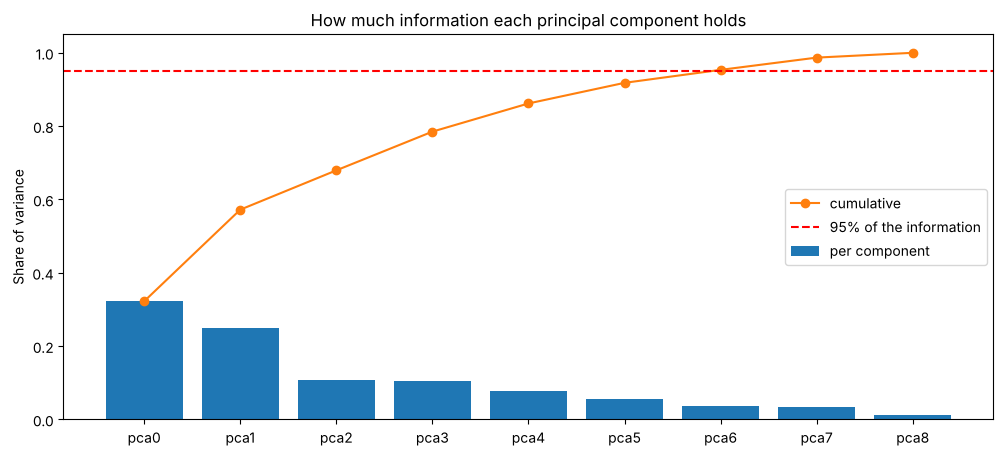

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(variance_df.index, variance_df['variance explained'], label='per component')
ax.plot(variance_df.index, variance_df['cumulative'], color='tab:orange', marker='o', label='cumulative')
ax.axhline(0.95, color='red', linestyle='--', label='95% of the information')
ax.set_ylabel('Share of variance')
ax.set_title('How much information each principal component holds')
ax.legend()
plt.show()

- The first component holds about a third of the information, the second about a quarter.
- After that, each component adds less and less.
- We need **7 of the 9 components to keep 95%** of the information. Our 9 features don't overlap much,
  so PCA can't shrink them a lot.

## 4. Keep 95% of the information
Instead of choosing the number of components ourselves, we tell PCA to keep as many as needed for 95%.

In [ ]:
my_pca = PCA(n_components=0.95)      # a number between 0 and 1 means "keep this share of the information"
pca_df = my_pca.fit_transform(scaled_df)

print(f'Kept {my_pca.n_components_} of {len(audio_features)} components, '
      f'{my_pca.explained_variance_ratio_.sum():.1%} of the information')
pca_df.head()

Kept 7 of 9 components, 95.3% of the information


,,pca0,pca1,pca2,pca3,pca4,pca5,pca6
name,artist,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,-1.116930,1.024670,2.148126,-0.825819,1.159901,-0.679893,0.208175
Saudade De Bahia,Antônio Carlos Jobim,-0.586614,2.091104,-0.102624,0.615671,-0.156993,0.260304,-0.454468
"Canta Canta, Minha Gente",Martinho Da Vila,0.694455,1.705717,-0.689561,-1.461903,2.127420,0.557610,-0.352923
Mulher Eu Sei,Chico César,-1.683491,1.955138,1.813732,-0.572574,0.820468,-0.087509,-0.219679
Rosa Morena,Kurt Elling,-2.147320,1.914442,0.026944,0.518301,0.451746,-0.505869,-0.254567


## 7. Conclusion
- **PCA 95% (7 components)** gives about the same quality as no PCA on the original features.
- With only 9 well-chosen features there isn't much noise to remove, so PCA's effect is modest. 

**Decision for the final model:** PowerTransformer → PCA (95%, 7 components) → K-Means.

**Next:** `04_final_analysis.ipynb`, the full pipeline and the final playlists.